<a href="https://colab.research.google.com/github/hkubra00/GROUP02_CENG313/blob/main/assignment1_eda_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Jane Street Real-Time Market Data Forecasting

**Course:** CENG313 - Data Science
**Assignment:** 1 - Exploratory Data Analysis and Baseline Models
**Competition:** [Jane Street Real-Time Market Data Forecasting](https://www.kaggle.com/competitions/jane-street-real-time-market-data-forecasting)

## 1. Project Overview

This project focuses on predicting financial market responses using historical
market data provided by the Jane Street Kaggle competition.

The objective is to predict `responder_6` using the available market features
and historical information.

## 2. Objectives

- Explore and understand the dataset.
- Analyze feature distributions and relationships.
- Investigate missing values and temporal patterns.
- Develop baseline regression models.
- Evaluate model performance using the competition's weighted R² metric.

In [1]:
# Clone the project repository

!git clone https://github.com/hkubra00/GROUP02_CENG313.git

Cloning into 'GROUP02_CENG313'...
remote: Enumerating objects: 20, done.
remote: Counting objects: 100% (20/20), done.
remote: Compressing objects: 100% (17/17), done.
remote: Total 20 (delta 3), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (20/20), 135.69 KiB | 1.14 MiB/s, done.
Resolving deltas: 100% (3/3), done.


In [2]:
import os
import sys
from pathlib import Path

PROJECT_ROOT = Path("/content/GROUP02_CENG313")

os.chdir(PROJECT_ROOT)

sys.path.insert(0, str(PROJECT_ROOT))

print("Project directory:", PROJECT_ROOT)
print("Project files:", os.listdir(PROJECT_ROOT))

Project directory: /content/GROUP02_CENG313
Project files: ['.gitignore', 'assignment1_eda_baseline.ipynb', 'src', '.git', 'README.md']


In [3]:
!pip install -q polars pyarrow lightgbm

In [4]:
!pip install -q xgboost catboost

In [5]:
# Standard libraries
import os
import sys
import gc
import warnings

from pathlib import Path

# Data processing
import numpy as np
import pandas as pd
import polars as pl

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

import lightgbm as lgb

# Configuration
SEED = 42

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

print("All libraries imported successfully.")

All libraries imported successfully.


In [6]:
import os
from google.colab import userdata

os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")

# Verify authentication by listing competition files
!kaggle competitions files -c jane-street-real-time-market-data-forecasting | head -n 15

Next Page Token = CfDJ8CXkJvnxKG5Ktgac76JjV5E5kzGUop8m986WHrU3g4rz075r3ig2EWtB_NLfGhDAn-QbamQ-zhrwYMp8F-R1mGgCl6bM7Q_TPLm8anHZI1d_ZkMt3M5CAU_rrdxBRuoFpgtq8XDD517SBn5ce7qPOQCUCDM5T7AAbTZfe-K-qwDSqigtqz4
name                                                                  size  creationDate                
--------------------------------------------------------------  ----------  --------------------------  
features.csv                                                          8857  2025-03-05 17:28:23.785000  
kaggle_evaluation/__init__.py                                          708  2025-03-05 17:28:23.772000  
kaggle_evaluation/core/__init__.py                                      83  2025-03-05 17:28:23.812000  
kaggle_evaluation/core/base_gateway.py                               14744  2025-03-05 17:28:23.827000  
kaggle_evaluation/core/generated/__init__.py                            83  2025-03-05 17:28:23.840000  
kaggle_evaluation/core/generated/kaggle_evaluation_pb2.py      

In [7]:
# 1. Download archive to Colab VM disk
!kaggle competitions download -c jane-street-real-time-market-data-forecasting -p /content

# 2. Extract into ./jane_street_data and delete the zip archive to free 11.5 GB
!unzip -q -o /content/jane-street-real-time-market-data-forecasting.zip -d ./jane_street_data
!rm -f /content/jane-street-real-time-market-data-forecasting.zip

# 3. Verify extracted files and remaining disk space
!ls -lh ./jane_street_data
!df -h /content

100% 11.5G/11.5G [02:13<00:00, 92.5MB/s]

total 36K
-rw-r--r--  1 root root 8.7K Mar  5  2025 features.csv
drwxr-xr-x  3 root root 4.0K Nov 11 09:04 kaggle_evaluation
drwxr-xr-x  3 root root 4.0K Nov 11 09:04 lags.parquet
-rw-r--r--  1 root root  403 Mar  5  2025 responders.csv
-rw-r--r--  1 root root  282 Mar  5  2025 sample_submission.csv
drwxr-xr-x  3 root root 4.0K Nov 11 09:04 test.parquet
drwxr-xr-x 12 root root 4.0K Nov 11 09:06 train.parquet
Filesystem      Size  Used Avail Use% Mounted on
overlay         113G   12G  101G  11% /


In [8]:
import glob
import polars as pl
import pandas as pd

TRAIN_PATH = "./jane_street_data/train.parquet"
TEST_PATH = "./jane_street_data/test.parquet"
LAGS_PATH = "./jane_street_data/lags.parquet"

# 1. Inspect Hive Partition Structure & File Sizes
train_files = sorted(glob.glob(f"{TRAIN_PATH}/**/*.parquet", recursive=True))
print(f"Total Hive Partitions in train.parquet: {len(train_files)}")
for p in train_files:
    size_mb = os.path.getsize(p) / (1024 ** 2)
    print(f"  - {p} ({size_mb:.1f} MB)")

# 2. Inspect Metadata CSVs
features_meta = pd.read_csv("./jane_street_data/features.csv")
responders_meta = pd.read_csv("./jane_street_data/responders.csv")
print("\n=== features.csv Shape & Preview ===")
print(f"Shape: {features_meta.shape}")
print(features_meta.head(5))

print("\n=== responders.csv Shape & Preview ===")
print(f"Shape: {responders_meta.shape}")
print(responders_meta)

# 3. Lazy Schema Resolution & Type-Aware Feature Separation
lazy_train = pl.scan_parquet(TRAIN_PATH)
schema = lazy_train.collect_schema()

all_feature_cols = [c for c in schema.names() if c.startswith("feature_")]
cont_feature_cols = [c for c in all_feature_cols if schema[c] in (pl.Float32, pl.Float64)]
disc_feature_cols = [c for c in all_feature_cols if schema[c] not in (pl.Float32, pl.Float64)]
responder_cols = [c for c in schema.names() if c.startswith("responder_")]
META_COLS = ["date_id", "time_id", "symbol_id", "weight"]
TARGET_COL = "responder_6"

print("\n=== Schema Breakdown ===")
print(f"Total Columns              : {len(schema)}")
print(f"Metadata Columns           : {META_COLS + ['partition_id']}")
print(f"Total Feature Columns      : {len(all_feature_cols)}")
print(f"  - Continuous (Float32)   : {len(cont_feature_cols)}")
print(f"  - Discrete (Int8/Int16)  : {len(disc_feature_cols)} -> {disc_feature_cols}")
print(f"Responder Target Columns   : {responder_cols}")

# 4. Global Summary Metrics via Single-Pass Streaming
dataset_overview = (
    lazy_train
    .select([
        pl.len().alias("total_rows"),
        pl.col("date_id").min().alias("min_date_id"),
        pl.col("date_id").max().alias("max_date_id"),
        pl.col("date_id").n_unique().alias("unique_days"),
        pl.col("symbol_id").n_unique().alias("unique_symbols"),
        pl.col("time_id").min().alias("min_time_id"),
        pl.col("time_id").max().alias("max_time_id")
    ])
    .collect(streaming=True)
)
print("\n=== Dataset Global Boundaries ===")
print(dataset_overview)

# 5. Preview First 5 Rows of train.parquet and lags.parquet
print("\n=== First 5 Rows of train.parquet ===")
print(lazy_train.head(5).collect())

print("\n=== First 5 Rows of lags.parquet ===")
print(pl.scan_parquet(LAGS_PATH).head(5).collect())

Total Hive Partitions in train.parquet: 10
  - ./jane_street_data/train.parquet/partition_id=0/part-0.parquet (448.6 MB)
  - ./jane_street_data/train.parquet/partition_id=1/part-0.parquet (679.1 MB)
  - ./jane_street_data/train.parquet/partition_id=2/part-0.parquet (758.0 MB)
  - ./jane_street_data/train.parquet/partition_id=3/part-0.parquet (1003.6 MB)
  - ./jane_street_data/train.parquet/partition_id=4/part-0.parquet (1261.4 MB)
  - ./jane_street_data/train.parquet/partition_id=5/part-0.parquet (1341.9 MB)
  - ./jane_street_data/train.parquet/partition_id=6/part-0.parquet (1555.1 MB)
  - ./jane_street_data/train.parquet/partition_id=7/part-0.parquet (1584.8 MB)
  - ./jane_street_data/train.parquet/partition_id=8/part-0.parquet (1533.8 MB)
  - ./jane_street_data/train.parquet/partition_id=9/part-0.parquet (1563.6 MB)

=== features.csv Shape & Preview ===
Shape: (79, 18)
      feature  tag_0  tag_1  tag_2  tag_3  tag_4  tag_5  tag_6  tag_7  tag_8  \
0  feature_00  False  False   True  

Total Rows Audited: 47,127,338
  - Complete Features (0% null)       : 32
  - Low Missingness (0% < null <= 5%) : 34
  - Moderate Missingness (5% - 20%)   : 13
  - High Missingness (> 20% null)     : 0

=== Top 20 Features by Missing Value Percentage ===
    column   group   dtype  null_count  null_pct
feature_27 feature Float32     8435985 17.900406
feature_26 feature Float32     8435985 17.900406
feature_21 feature Float32     8435985 17.900406
feature_31 feature Float32     8435985 17.900406
feature_39 feature Float32     4300649  9.125593
feature_42 feature Float32     4300649  9.125593
feature_53 feature Float32     4254098  9.026816
feature_50 feature Float32     4254098  9.026816
feature_00 feature Float32     3182052  6.752030
feature_01 feature Float32     3182052  6.752030
feature_02 feature Float32     3182052  6.752030
feature_03 feature Float32     3182052  6.752030
feature_04 feature Float32     3182052  6.752030
feature_15 feature Float32     1209299  2.566024
feature_41

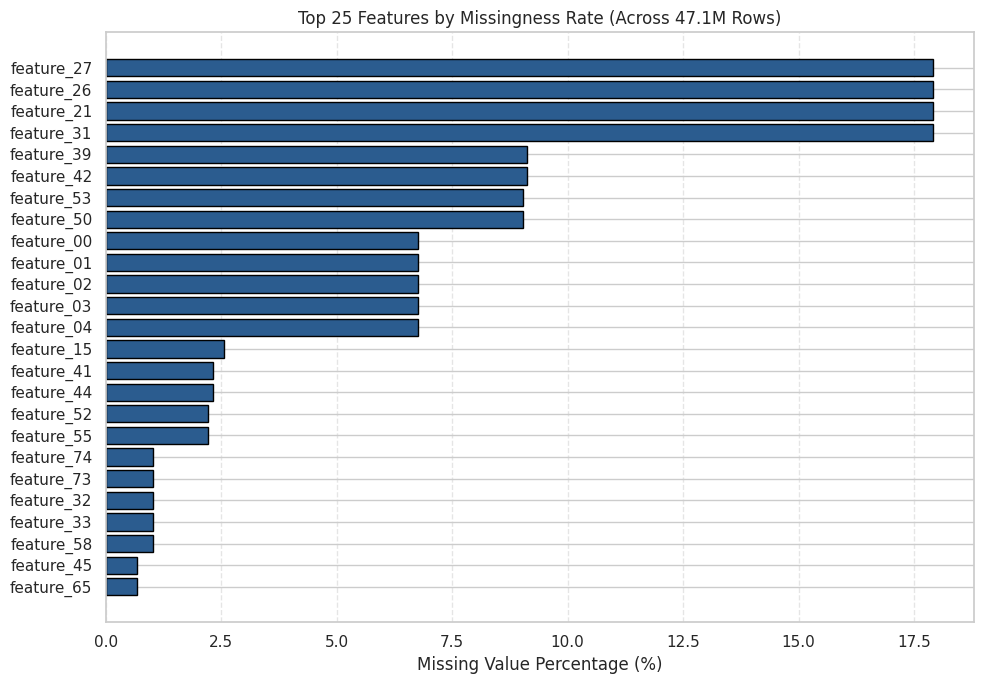

In [9]:
import pyarrow.parquet as pq
import matplotlib.pyplot as plt

PLOTS_DIR = "./plots"
OUTPUT_DIR = "./preprocessed_folds"
os.makedirs(PLOTS_DIR, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

# 1. Extract Exact Null Counts from Parquet Row-Group Footers (Zero RAM)
first_meta = pq.read_metadata(train_files[0])
col_index_map = {first_meta.schema.names[i]: i for i in range(first_meta.num_columns)}

cols_to_audit = META_COLS + all_feature_cols + responder_cols
null_counts = {c: 0 for c in cols_to_audit}
total_rows = 0

for filepath in train_files:
    meta = pq.read_metadata(filepath)
    total_rows += meta.num_rows
    for rg_idx in range(meta.num_row_groups):
        rg = meta.row_group(rg_idx)
        for c in cols_to_audit:
            if c in col_index_map:
                col_stats = rg.column(col_index_map[c]).statistics
                if col_stats and col_stats.has_null_count:
                    null_counts[c] += col_stats.null_count

null_df = pd.DataFrame([
    {
        "column": c,
        "group": "feature" if c.startswith("feature_") else ("responder" if c.startswith("responder_") else "meta"),
        "dtype": str(schema[c]),
        "null_count": null_counts[c],
        "null_pct": (null_counts[c] / total_rows) * 100
    }
    for c in cols_to_audit
])

feature_null_df = null_df[null_df["group"] == "feature"].sort_values("null_pct", ascending=False).reset_index(drop=True)

# 2. Missingness Severity Summary
complete_feats = (feature_null_df["null_count"] == 0).sum()
low_missing = ((feature_null_df["null_pct"] > 0) & (feature_null_df["null_pct"] <= 5.0)).sum()
mod_missing = ((feature_null_df["null_pct"] > 5.0) & (feature_null_df["null_pct"] <= 20.0)).sum()
high_missing = (feature_null_df["null_pct"] > 20.0).sum()

print(f"Total Rows Audited: {total_rows:,}")
print(f"  - Complete Features (0% null)       : {complete_feats}")
print(f"  - Low Missingness (0% < null <= 5%) : {low_missing}")
print(f"  - Moderate Missingness (5% - 20%)   : {mod_missing}")
print(f"  - High Missingness (> 20% null)     : {high_missing}")

print("\n=== Top 20 Features by Missing Value Percentage ===")
print(feature_null_df.head(20).to_string(index=False))

print("\n=== Metadata & Responder Missing Value Audit ===")
print(null_df[null_df["group"] != "feature"].to_string(index=False))

# 3. Visualization: Top 25 Features by Missingness Percentage
top25_nulls = feature_null_df.head(25).iloc[::-1]
plt.figure(figsize=(10, 7))
plt.barh(top25_nulls["column"], top25_nulls["null_pct"], color="#2b5c8f", edgecolor="black")
plt.xlabel("Missing Value Percentage (%)")
plt.title("Top 25 Features by Missingness Rate (Across 47.1M Rows)")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig(f"{PLOTS_DIR}/missing_values_top25.png", dpi=150)
plt.show()

=== Primary Target (responder_6) & Weight Distribution Summary ===
  min               : -5.0
  max               : 5.0
  mean              : -0.002140649128705263
  std               : 0.8898516297340393
  skewness          : 0.46889423691998633
  kurtosis          : 6.863651622126461
  clipped_at_neg5   : 49535
  clipped_at_pos5   : 107216
  zero_weight_rows  : 0
  weight_mean       : 2.0094454288482666
  weight_max        : 10.240419387817383

=== All Responders (responder_0 .. responder_8) Comparison ===
  responder      mean      std
responder_0 -0.001545 0.591211
responder_1 -0.000866 0.587551
responder_2 -0.000142 0.599179
responder_3 -0.016380 0.819231
responder_4 -0.012442 0.872840
responder_5 -0.016624 0.734546
responder_6 -0.002141 0.889852
responder_7  0.001476 0.916042
responder_8 -0.001114 0.864412

=== responder_6 Empirical Quantiles ===
  Quantile   0.1% : -5.00000
  Quantile   1.0% : -2.49171
  Quantile   5.0% : -1.27783
  Quantile  25.0% : -0.38177
  Quantile  50.0% :

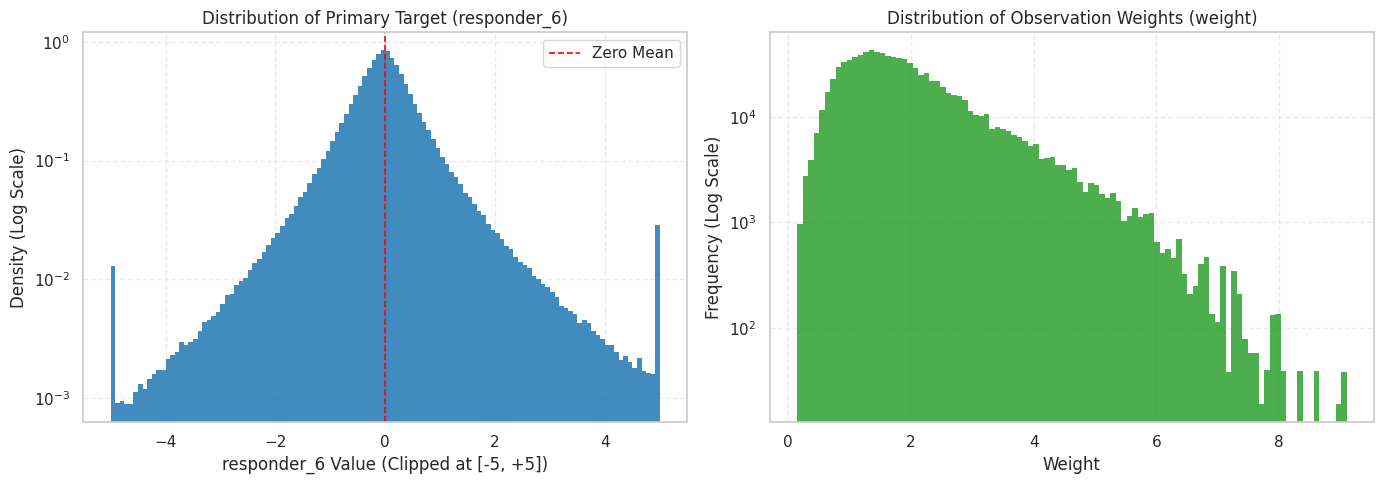

In [10]:
# 1. Streaming Statistical Profile of Primary Target (responder_6) and Weights
target_stats = (
    lazy_train
    .select([
        pl.col("responder_6").min().alias("min"),
        pl.col("responder_6").max().alias("max"),
        pl.col("responder_6").mean().alias("mean"),
        pl.col("responder_6").std().alias("std"),
        pl.col("responder_6").skew().alias("skewness"),
        pl.col("responder_6").kurtosis().alias("kurtosis"),
        (pl.col("responder_6") == -5.0).sum().alias("clipped_at_neg5"),
        (pl.col("responder_6") == 5.0).sum().alias("clipped_at_pos5"),
        (pl.col("weight") <= 0).sum().alias("zero_weight_rows"),
        pl.col("weight").mean().alias("weight_mean"),
        pl.col("weight").max().alias("weight_max")
    ])
    .collect(streaming=True)
)

print("=== Primary Target (responder_6) & Weight Distribution Summary ===")
for col in target_stats.columns:
    print(f"  {col:18s}: {target_stats[col][0]}")

# 2. Compare Mean & Std Across All 9 Responders (responder_0 .. responder_8)
resp_exprs = []
for r in responder_cols:
    resp_exprs.append(pl.col(r).mean().alias(f"{r}_mean"))
    resp_exprs.append(pl.col(r).std().alias(f"{r}_std"))

resp_summary_raw = lazy_train.select(resp_exprs).collect(streaming=True).to_dicts()[0]
resp_table = pd.DataFrame([
    {"responder": r, "mean": resp_summary_raw[f"{r}_mean"], "std": resp_summary_raw[f"{r}_std"]}
    for r in responder_cols
])
print("\n=== All Responders (responder_0 .. responder_8) Comparison ===")
print(resp_table.to_string(index=False))

# 3. Strided Sample (Every 50th Row = ~942,000 Rows) for Quantiles & Histograms
target_sample = (
    lazy_train
    .select(["date_id", "symbol_id", "weight", "responder_6"])
    .gather_every(50)
    .collect(streaming=True)
)

r6_np = target_sample["responder_6"].drop_nulls().to_numpy()
w_np = target_sample["weight"].drop_nulls().to_numpy()

quantiles = np.quantile(r6_np, [0.001, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999])
print("\n=== responder_6 Empirical Quantiles ===")
for q, val in zip([0.001, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999], quantiles):
    print(f"  Quantile {q*100:5.1f}% : {val:+.5f}")

# 4. Plot Target & Weight Distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(r6_np, bins=120, color="#1f77b4", edgecolor="none", alpha=0.85, density=True)
axes[0].axvline(0.0, color="red", linestyle="--", linewidth=1.2, label="Zero Mean")
axes[0].set_title("Distribution of Primary Target (responder_6)")
axes[0].set_xlabel("responder_6 Value (Clipped at [-5, +5])")
axes[0].set_ylabel("Density (Log Scale)")
axes[0].set_yscale("log")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.4)

axes[1].hist(w_np, bins=100, color="#2ca02c", edgecolor="none", alpha=0.85)
axes[1].set_title("Distribution of Observation Weights (weight)")
axes[1].set_xlabel("Weight")
axes[1].set_ylabel("Frequency (Log Scale)")
axes[1].set_yscale("log")
axes[1].grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig(f"{PLOTS_DIR}/target_and_weight_distribution.png", dpi=150)
plt.show()

In [11]:
import json

min_date = int(dataset_overview["min_date_id"][0])
max_date = int(dataset_overview["max_date_id"][0])

N_SPLITS = 4
PURGE_DAYS = 5
MAX_TRAIN_DAYS = 500

def make_purged_splits(min_d, max_d, n_splits=4, purge_days=5, max_train_days=None):
    total_span = (max_d - min_d + 1)
    chunk = total_span // (n_splits + 1)
    splits = []
    for i in range(1, n_splits + 1):
        train_end = min_d + (i * chunk) - purge_days - 1
        train_start = min_d if max_train_days is None else max(min_d, train_end - max_train_days + 1)
        val_start = min_d + (i * chunk)
        val_end = val_start + chunk - 1 if i < n_splits else max_d
        splits.append({
            "fold": i,
            "train_range": (int(train_start), int(train_end)),
            "val_range": (int(val_start), int(val_end))
        })
    return splits

cv_splits = make_purged_splits(min_date, max_date, n_splits=N_SPLITS, purge_days=PURGE_DAYS, max_train_days=MAX_TRAIN_DAYS)
for s in cv_splits:
    t0, t1 = s["train_range"]
    v0, v1 = s["val_range"]
    print(f"Fold {s['fold']}: Train [{t0}..{t1}] ({t1-t0+1}d) -> Purge {PURGE_DAYS}d -> Val [{v0}..{v1}] ({v1-v0+1}d)")

def compute_training_stats_batched(lazy_df, train_range, cont_cols, batch_size=20):
    t_min, t_max = train_range
    train_slice = lazy_df.filter((pl.col("date_id") >= t_min) & (pl.col("date_id") <= t_max))
    means, stds = {}, {}
    for i in range(0, len(cont_cols), batch_size):
        batch = cont_cols[i : i + batch_size]
        exprs = []
        for c in batch:
            exprs.append(pl.col(c).cast(pl.Float64).mean().alias(f"{c}__mean"))
            exprs.append(pl.col(c).cast(pl.Float64).std().alias(f"{c}__std"))
        stats_row = train_slice.select(exprs).collect(streaming=True).to_dicts()[0]
        for c in batch:
            m = stats_row[f"{c}__mean"]
            s = stats_row[f"{c}__std"]
            means[c] = float(m) if (m is not None and m == m) else 0.0
            stds[c] = float(s) if (s is not None and s == s and s > 1e-8) else 1.0
        print(f"  Computed stats for features {i+1}..{min(i+batch_size, len(cont_cols))}/{len(cont_cols)}")
    return means, stds

def build_standardized_zero_imputed_lazy(
    lazy_df, date_range, cont_cols, disc_cols, means, stds,
    clip_bound=10.0, filter_positive_weights=True
):
    d_min, d_max = date_range
    sub_lazy = lazy_df.filter((pl.col("date_id") >= d_min) & (pl.col("date_id") <= d_max))
    if filter_positive_weights:
        sub_lazy = sub_lazy.filter(pl.col("weight") > 0)

    cont_exprs = [
        (
            ((pl.col(c).cast(pl.Float32) - means[c]) / stds[c])
            .clip(-clip_bound, clip_bound)
            .fill_nan(0.0)
            .fill_null(0.0)
            .cast(pl.Float32)
            .alias(c)
        )
        for c in cont_cols
    ]
    disc_exprs = [pl.col(c).fill_null(0).cast(pl.Float32).alias(c) for c in disc_cols]
    meta_exprs = [
        pl.col("date_id").cast(pl.Int16),
        pl.col("time_id").cast(pl.Int16),
        pl.col("symbol_id").fill_null(-1).cast(pl.Int16),
        pl.col("weight").fill_null(0.0).cast(pl.Float32),
        pl.col(TARGET_COL).fill_null(0.0).cast(pl.Float32)
    ]
    selected_cols = META_COLS + [TARGET_COL] + cont_cols + disc_cols
    return sub_lazy.with_columns(cont_exprs + disc_exprs + meta_exprs).select(selected_cols)

active_fold = cv_splits[-1]
fold_id = active_fold["fold"]
means, stds = compute_training_stats_batched(lazy_train, active_fold["train_range"], cont_feature_cols, batch_size=20)

with open(f"{OUTPUT_DIR}/fold{fold_id}_scaler.json", "w") as f:
    json.dump({"means": means, "stds": stds}, f, indent=2)

train_proc_lazy = build_standardized_zero_imputed_lazy(
    lazy_train, active_fold["train_range"], cont_feature_cols, disc_feature_cols, means, stds
)
val_proc_lazy = build_standardized_zero_imputed_lazy(
    lazy_train, active_fold["val_range"], cont_feature_cols, disc_feature_cols, means, stds
)

train_out = f"{OUTPUT_DIR}/fold{fold_id}_train.parquet"
val_out = f"{OUTPUT_DIR}/fold{fold_id}_val.parquet"

train_proc_lazy.sink_parquet(train_out, compression="zstd")
val_proc_lazy.sink_parquet(val_out, compression="zstd")

Fold 1: Train [0..333] (334d) -> Purge 5d -> Val [339..677] (339d)
Fold 2: Train [173..672] (500d) -> Purge 5d -> Val [678..1016] (339d)
Fold 3: Train [512..1011] (500d) -> Purge 5d -> Val [1017..1355] (339d)
Fold 4: Train [851..1350] (500d) -> Purge 5d -> Val [1356..1698] (343d)
  Computed stats for features 1..20/76
  Computed stats for features 21..40/76
  Computed stats for features 41..60/76
  Computed stats for features 61..76/76


In [12]:
scaler_summary = pd.DataFrame({
    "feature": list(means.keys()),
    "train_mean": list(means.values()),
    "train_std": list(stds.values())
})
print(scaler_summary.head(15).to_string(index=False))

   feature  train_mean  train_std
feature_00    0.254785   1.117385
feature_01   -0.020989   1.084906
feature_02    0.257578   1.115047
feature_03    0.257038   1.115179
feature_04   -0.001496   1.045540
feature_05   -0.063875   1.004187
feature_06   -0.008914   1.065896
feature_07   -0.023538   1.053844
feature_08    0.135365   0.961449
feature_12   -0.033370   0.985884
feature_13   -0.031610   0.938205
feature_14   -0.048168   0.985065
feature_15   -0.217113   0.925064
feature_16   -0.165548   0.898414
feature_17   -0.205607   0.920695


Fold 4 verilerinin 'Ultra-Hafif' versiyonu RAM'e yükleniyor...
Train boyutu: (500000, 79) | Val boyutu: (100000, 79)

1/3: Zero Baseline değerlendiriliyor...
2/3: Ridge Regression eğitiliyor...
3/3: LightGBM Regressor eğitiliyor...

=== Baseline Modelleri Performans Karşılaştırması ===
                       Model  Train Weighted R2  Val Weighted R2  Süre (sn)
        Zero Baseline (Naif)           0.000000         0.000000       0.01
Ridge Regression (alpha=100)           0.009488        -0.005350       0.80
          LightGBM Regressor           0.033057         0.002207      15.37


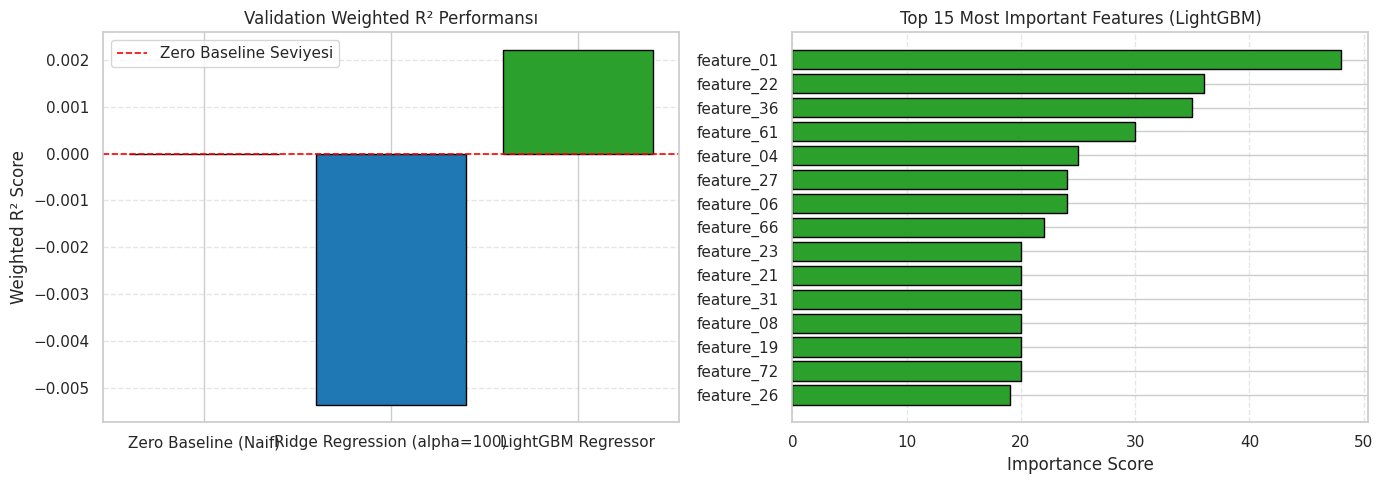

28514

In [13]:
import time
import gc
import importlib
import pandas as pd
import matplotlib.pyplot as plt

import src.utils
import src.models
importlib.reload(src.utils)
importlib.reload(src.models)

from src.utils import weighted_r2_score, load_fold_arrays
from src.models import ZeroBaseline, RidgeBaseline, LGBMBaseline

# 1. Özellik listesini birleştir
feature_cols = cont_feature_cols + disc_feature_cols

print("Fold 4 verilerinin 'Ultra-Hafif' versiyonu RAM'e yükleniyor...")
# KESİN ÇÖZÜM: Train 500 bin, Val 100 bin satıra düşürüldü. RAM %100 dayanacaktır.
X_train, y_train, w_train = load_fold_arrays(train_out, feature_cols, TARGET_COL, max_rows=500_000)
X_val, y_val, w_val = load_fold_arrays(val_out, feature_cols, TARGET_COL, max_rows=100_000)
print(f"Train boyutu: {X_train.shape} | Val boyutu: {X_val.shape}\n")

results = []

# --- 1. Zero Baseline ---
print("1/3: Zero Baseline değerlendiriliyor...")
t0 = time.time()
zero_model = ZeroBaseline().fit(X_train, y_train, w_train=w_train)
zero_val_pred = zero_model.predict(X_val)
results.append({
    "Model": "Zero Baseline (Naif)",
    "Train Weighted R2": 0.0,
    "Val Weighted R2": weighted_r2_score(y_val, zero_val_pred, w_val),
    "Süre (sn)": round(time.time() - t0, 2)
})

del zero_model, zero_val_pred
gc.collect()


# --- 2. Ridge Regression Baseline ---
print("2/3: Ridge Regression eğitiliyor...")
t0 = time.time()
ridge_model = RidgeBaseline(alpha=100.0).fit(X_train, y_train, w_train=w_train)
ridge_train_pred = ridge_model.predict(X_train)
ridge_val_pred = ridge_model.predict(X_val)
results.append({
    "Model": "Ridge Regression (alpha=100)",
    "Train Weighted R2": weighted_r2_score(y_train, ridge_train_pred, w_train),
    "Val Weighted R2": weighted_r2_score(y_val, ridge_val_pred, w_val),
    "Süre (sn)": round(time.time() - t0, 2)
})

del ridge_model, ridge_train_pred, ridge_val_pred
gc.collect()


# --- 3. LightGBM Regressor Baseline ---
print("3/3: LightGBM Regressor eğitiliyor...")
t0 = time.time()
lgb_model = LGBMBaseline().fit(X_train, y_train, w_train=w_train, X_val=X_val, y_val=y_val, w_val=w_val)
lgb_train_pred = lgb_model.predict(X_train)
lgb_val_pred = lgb_model.predict(X_val)
results.append({
    "Model": "LightGBM Regressor",
    "Train Weighted R2": weighted_r2_score(y_train, lgb_train_pred, w_train),
    "Val Weighted R2": weighted_r2_score(y_val, lgb_val_pred, w_val),
    "Süre (sn)": round(time.time() - t0, 2)
})

lgb_importances = lgb_model.model.feature_importances_
del lgb_model, lgb_train_pred, lgb_val_pred
gc.collect()


# --- 4. Raporlama ve Çizdirme ---
results_df = pd.DataFrame(results)
print("\n=== Baseline Modelleri Performans Karşılaştırması ===")
print(results_df.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(results_df["Model"], results_df["Val Weighted R2"], color=["#7f7f7f", "#1f77b4", "#2ca02c"], edgecolor="black")
axes[0].axhline(0.0, color="red", linestyle="--", linewidth=1.2, label="Zero Baseline Seviyesi")
axes[0].set_title("Validation Weighted R² Performansı")
axes[0].set_ylabel("Weighted R² Score")
axes[0].grid(axis="y", linestyle="--", alpha=0.5)
axes[0].legend()

feat_imp_df = pd.DataFrame({
    "feature": feature_cols,
    "importance": lgb_importances
}).sort_values("importance", ascending=False).head(15)

axes[1].barh(feat_imp_df["feature"][::-1], feat_imp_df["importance"][::-1], color="#2ca02c", edgecolor="black")
axes[1].set_title("Top 15 Most Important Features (LightGBM)")
axes[1].set_xlabel("Importance Score")
axes[1].grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig(f"{PLOTS_DIR}/optimized_baseline_comparison.png", dpi=150)
plt.show()

gc.collect()